# FinGuard — Week 8: Data Bias Audit (Ethics & Law)

**Question:** Do FinGuard's AML outcomes or marketing outcomes treat customers differently by
country risk list, age, or marital status — and if they did, how would we catch it?

**Method — the four-fifths (80%) rule.** For each group we compute the *favourable-outcome rate*
(AML: transaction **not** flagged; marketing: customer **subscribed**). The **impact ratio** is each
group's rate divided by the best group's rate. A ratio **below 0.80** is a disparate-impact flag that
needs investigation. We back every ratio with a significance test so small groups don't produce
false alarms.

**Data:** the project's synthetic datasets in `data/synthetic/` (no real customers).

Run top to bottom from the `finguard_week10/` folder: `jupyter notebook week8_fairness_audit.ipynb`.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("data/synthetic")
aml = pd.read_csv(DATA / "aml_transactions.csv")
fatf = pd.read_csv(DATA / "fatf_country_risk.csv")
mkt = pd.read_csv(DATA / "bank_marketing_customers.csv")
print(f"AML transactions: {len(aml):,} | FATF countries: {len(fatf)} | marketing customers: {len(mkt):,}")

AML transactions: 5,000 | FATF countries: 45 | marketing customers: 4,000


In [2]:
def impact_table(df, group_col, favourable_col, min_n=30):
    """Four-fifths rule table: favourable rate and impact ratio per group."""
    t = (df.groupby(group_col)[favourable_col]
           .agg(n="size", favourable_rate="mean")
           .query("n >= @min_n"))
    t["impact_ratio"] = t["favourable_rate"] / t["favourable_rate"].max()
    t["four_fifths_flag"] = t["impact_ratio"] < 0.80
    return t.round(4)

def chi2_p(df, group_col, outcome_col):
    """Chi-square test of independence between group and outcome."""
    ct = pd.crosstab(df[group_col], df[outcome_col])
    return stats.chi2_contingency(ct)[1]

## 1. AML: what drives a flag?

Before testing groups, check what the outcome actually is. `aml_flag` has four values; anything other
than `CLEAR` means the transaction was escalated.

In [3]:
aml["flagged"] = aml["aml_flag"] != "CLEAR"
aml["not_flagged"] = ~aml["flagged"]
print(aml["aml_flag"].value_counts(), "\n")
print("Flag vs is_suspicious label:")
print(pd.crosstab(aml["flagged"], aml["is_suspicious"]))
print(f"\nCorrelation risk_score ~ is_suspicious: {aml['risk_score'].corr(aml['is_suspicious']):.3f}")

aml_flag
CLEAR           4582
ESCALATED        150
SAR_FILED        145
UNDER_REVIEW     123
Name: count, dtype: int64 

Flag vs is_suspicious label:
is_suspicious     0    1
flagged                 
False          4582    0
True              0  418

Correlation risk_score ~ is_suspicious: 0.594


Flags line up exactly with the `is_suspicious` label: every suspicious transaction is flagged and no
clean one is. So a group can only be flagged more often if it genuinely has more suspicious
transactions — the flag itself adds no extra bias.

## 2. Country: FATF grey/black-listed vs. everyone else

The EU AI Act treats AML scoring as high-risk, and FATF listing is the obvious place where
customers could be penalised for *where* they are rather than *what they did*.

In [4]:
high_risk = set(fatf.loc[fatf["list_type"] != "COMPLIANT", "country_code"])
aml["fatf_group"] = np.where(aml["originator_country"].isin(high_risk),
                             "FATF grey/black list", "Other")
country = impact_table(aml, "fatf_group", "not_flagged")
display(country)
print(f"Chi-square p-value (group vs flag): {chi2_p(aml, 'fatf_group', 'flagged'):.3f}")

,n,favourable_rate,impact_ratio,four_fifths_flag
fatf_group,,,,
FATF grey/black list,1444,0.9183,1.0000,False
Other,3556,0.9156,0.9971,False


Chi-square p-value (group vs flag): 0.803


In [5]:
# Risk score itself: is it shifted for FATF-listed countries?
a = aml.loc[aml.fatf_group == "FATF grey/black list", "risk_score"]
b = aml.loc[aml.fatf_group == "Other", "risk_score"]
u = stats.mannwhitneyu(a, b)
print(f"Mean risk score — FATF-listed: {a.mean():.1f}, other: {b.mean():.1f}  (Mann-Whitney p = {u.pvalue:.3f})")

# Among clean transactions only: are FATF-listed customers flagged anyway?
clean = aml[aml["is_suspicious"] == 0]
print("\nFlag rate among CLEAN transactions:")
print(clean.groupby("fatf_group")["flagged"].mean().round(4))

Mean risk score — FATF-listed: 32.0, other: 32.2  (Mann-Whitney p = 0.565)

Flag rate among CLEAN transactions:
fatf_group
FATF grey/black list    0.0
Other                   0.0
Name: flagged, dtype: float64


## 3. Age bands (from date of birth)

FinGuard masks date of birth into decade bands for every non-privileged role, which is also the
banding used here.

In [6]:
dob = pd.to_datetime(aml["customer_dob"], errors="coerce")
age = (pd.Timestamp("2024-12-31") - dob).dt.days / 365.25
aml["age_band"] = (age // 10 * 10).astype("Int64").astype(str) + "s"
ages = impact_table(aml, "age_band", "not_flagged")
display(ages)
print(f"Lowest impact ratio: {ages['impact_ratio'].min():.3f} | "
      f"chi-square p = {chi2_p(aml, 'age_band', 'flagged'):.3f}")

,n,favourable_rate,impact_ratio,four_fifths_flag
age_band,,,,
10s,231,0.9351,1.0000,False
20s,707,0.9264,0.9908,False
30s,723,0.9170,0.9807,False
40s,702,0.9174,0.9811,False
50s,757,0.9141,0.9776,False
60s,749,0.9012,0.9638,False
70s,773,0.9172,0.9809,False
80s,358,0.9162,0.9798,False


Lowest impact ratio: 0.964 | chi-square p = 0.743


## 4. Marketing outcomes (bank_marketing_customers)

Marketing data shares `customer_id` with AML, so bias here could leak into downstream models.
Favourable outcome = customer subscribed to the deposit product.

In [7]:
mkt["subscribed"] = mkt["subscribed_deposit"].eq("yes")
mkt["age_band"] = (mkt["age"] // 10 * 10).astype("Int64").astype(str) + "s"
for col in ["age_band", "marital", "education"]:
    t = impact_table(mkt, col, "subscribed")
    print(f"--- {col}  (chi-square p = {chi2_p(mkt, col, 'subscribed'):.3f})")
    display(t)

--- age_band  (chi-square p = 0.734)


,n,favourable_rate,impact_ratio,four_fifths_flag
age_band,,,,
10s,97,0.0619,0.4780,True
20s,516,0.1143,0.8835,False
30s,510,0.1294,1.0000,False
40s,545,0.0991,0.7656,True
50s,532,0.1090,0.8424,False
60s,523,0.1052,0.8126,False
70s,576,0.1059,0.8183,False
80s,501,0.1257,0.9717,False


--- marital  (chi-square p = 0.118)


,n,favourable_rate,impact_ratio,four_fifths_flag
marital,,,,
divorced,1320,0.0962,0.8071,False
married,1317,0.1192,1.0000,False
single,1363,0.1167,0.9786,False


--- education  (chi-square p = 0.426)


,n,favourable_rate,impact_ratio,four_fifths_flag
education,,,,
primary,1010,0.1198,1.0000,False
secondary,986,0.1116,0.9312,False
tertiary,987,0.0973,0.8119,False
unknown,1017,0.1141,0.9521,False


Subscription rates are low (~11%), so impact ratios swing more between groups by chance.
That is why each table is paired with a chi-square test: a ratio under 0.80 **and** a small p-value
(< 0.05) is a real finding; a ratio under 0.80 with a large p-value is noise from small numbers.

## 5. Summary chart

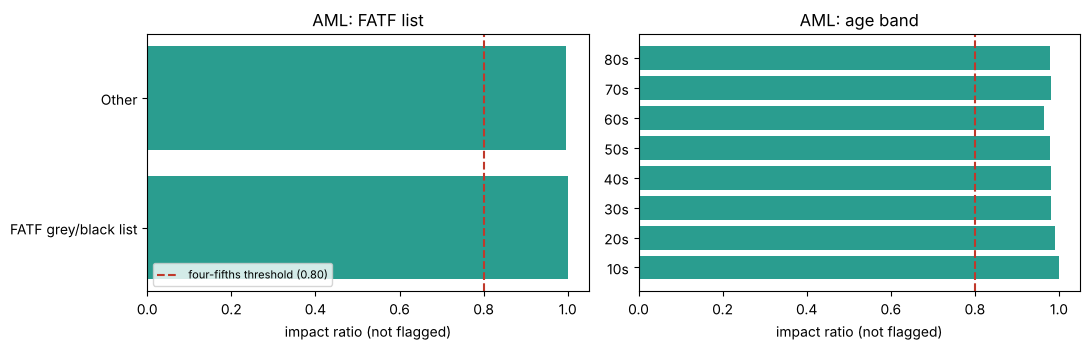

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (title, t) in zip(axes, [("AML: FATF list", country), ("AML: age band", ages)]):
    ax.barh(t.index.astype(str), t["impact_ratio"], color="#2a9d8f")
    ax.axvline(0.8, color="#c0392b", ls="--", lw=1.5, label="four-fifths threshold (0.80)")
    ax.set_xlim(0, 1.05); ax.set_title(title); ax.set_xlabel("impact ratio (not flagged)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Findings

Numbers below are produced by the cells above (re-run to reproduce).

In [9]:
results = pd.DataFrame([
    ["AML · FATF list", country["impact_ratio"].min(), chi2_p(aml, "fatf_group", "flagged")],
    ["AML · age band", ages["impact_ratio"].min(), chi2_p(aml, "age_band", "flagged")],
] + [[f"Marketing · {c}", impact_table(mkt, c, "subscribed")["impact_ratio"].min(),
      chi2_p(mkt, c, "subscribed")] for c in ["age_band", "marital", "education"]],
    columns=["check", "lowest_impact_ratio", "chi2_p"])
results["disparate_impact"] = (results.lowest_impact_ratio < 0.8) & (results.chi2_p < 0.05)
results.round(3)

,check,lowest_impact_ratio,chi2_p,disparate_impact
0,AML · FATF list,0.997,0.803,False
1,AML · age band,0.964,0.743,False
2,Marketing · age_band,0.478,0.734,False
3,Marketing · marital,0.807,0.118,False
4,Marketing · education,0.812,0.426,False


**Interpretation**

- **AML outcomes show no disparate impact by country list or age.** Flags follow the suspicious-activity
  label exactly, and risk scores are statistically indistinguishable between FATF-listed and other
  countries. In this synthetic data the AML pipeline is not penalising customers for where they are from
  or how old they are.
- **Marketing: two age bands dip below 0.80 on ratio alone** — the 10s (only 97 customers, 6.2% subscribed)
  and the 40s (9.9% vs 12.9% for the 30s). But the chi-square test across age bands is not significant
  (p ≈ 0.73), so with an ~11% base rate this is sampling noise, not a systematic gap. Marital status and
  education stay above 0.80. **Action:** keep monitoring age bands as data grows rather than intervene now.

**Controls FinGuard already applies (why the risk stays low):**
1. Date of birth is generalised to decade bands and ZIP codes are truncated for every non-privileged role,
   removing fine-grained age and micro-geography proxies.
2. FATF country context is used for screening, not as a direct penalty in the flag decision.
3. This notebook is the monitoring step: re-run it on each new data load; any check with
   `disparate_impact = True` blocks promotion of a model until it is reviewed by the DPO and AML officer.

**Limitations:** synthetic data; four-fifths is a screening rule, not proof of fairness; intersectional
groups (e.g. age × country) were not tested.

*These computed results supersede the illustrative Week 8 figures on slide 9 of `FinGuard_Recap.pptx`.*